In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

Dataset Sample:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


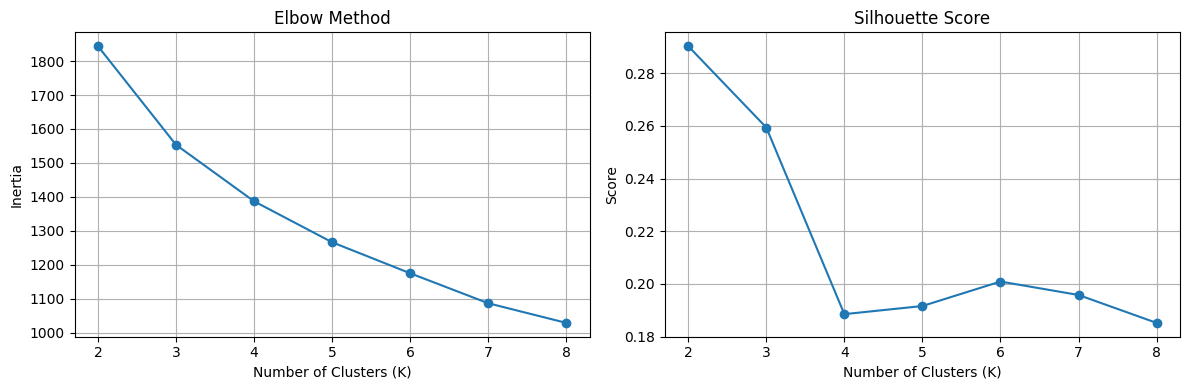

Selected K: 2
Average Spending per Cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,13973.13,2401.75,2918.71,3705.67,491.94,1038.04
1,9355.87,10346.36,14697.06,2222.45,6084.51,2177.43


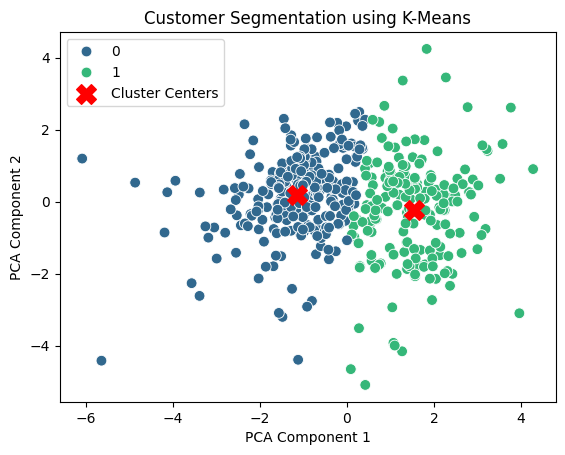

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Load the dataset
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00292/Wholesale%20customers%20data.csv"
df = pd.read_csv(url)

print("Dataset Sample:")
display(df.head())

# 2. Select the spending columns
features = ['Fresh', 'Milk', 'Grocery', 'Frozen',
            'Detergents_Paper', 'Delicassen']

X = df[features]

# 3. Prepare and scale the data
X_log = np.log1p(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

# 4. Evaluate different numbers of clusters
K_range = range(2, 9)
inertias = []
scores = []

for k in K_range:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    scores.append(silhouette_score(X_scaled, labels))

# 5. Plot evaluation results
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(list(K_range), inertias, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(list(K_range), scores, marker='o')
plt.title('Silhouette Score')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Score')
plt.grid(True)

plt.tight_layout()
plt.show()

# 6. Select K with the highest Silhouette Score
best_k = list(K_range)[np.argmax(scores)]
print("Selected K:", best_k)

# 7. Apply the final K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 8. Display the average spending per cluster
print("Average Spending per Cluster:")
display(df.groupby('Cluster')[features].mean().round(2))

# 9. Visualize clusters using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

centers_pca = pca.transform(kmeans.cluster_centers_)

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='viridis',
    s=60
)

plt.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker='X',
    s=200,
    color='red',
    label='Cluster Centers'
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend()
plt.show()